<h2 style="color: teal;">Trial project -- reproduce plot 5C</h2>
<h4 style="color: orange;">by Karl Vilhelmsson Emneby as trial project for Cam Allen's and Julian Yocum's super cool research.</h4>

<br>

#### 1. generate training data - INPUT (a,b) sets and the integral OUTPUT

#### 2. build + train transformer on the INPUT+OUTPUT

#### 3. train 1000 linear field probes on specific (a,b) 

#### 4. run PCA on the manifold to extract top "basis vectors"

#### 5. plot approx's of the feature field for different # of PCs

<br>

In [1]:
import numpy as np
from scipy import integrate, stats
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

### 0: hyperparam's

In [2]:
lr = 1e-4
epochs = 2000
phi_steps = 1000
# specific (a,b) to run 5c on
a_viz, b_viz = 20.0, 20.0

### 1. data generation

In [3]:
# make function for calculating target
def compute_target(a, b, num_points=1000):
    def integrand(phi):
        beta_val = stats.beta.pdf(phi, a, b)
        cos_val = np.cos(7 * np.pi * phi)
        return beta_val * cos_val
    
    result, _ = integrate.quad(integrand, 0, 1)
    return result

# unique (a,b) combos from 1-50
a_values = np.arange(1, 51)  # 1 to 50
b_values = np.arange(1, 51)  # 1 to 50

# NEW - this ended up not improving the result...
#a_values = np.linspace(1, 50, 200)  # 100 values from 1 to 50
# b_values = np.linspace(1, 50, 200)  # gives 40,000 total combinations

all_params = [(a, b) for a in a_values for b in b_values] # (1,1), (1,2), ..., (50,50)


params = np.array(all_params)  # easier to turn tuples list into np array

targets = np.array([compute_target(a, b) for a, b in params])

# shuffle indices (no longer 0,1,2,3,...,2499 but random order) 
# then split (60/40)
indices = np.random.permutation(len(params))
split_idx = int(0.6 * len(params))  # the int 1500 in our case

# have the 60% random first indices go to training
train_params = params[indices[:split_idx]]
train_targets = targets[indices[:split_idx]]
# rest to testing
test_params = params[indices[split_idx:]]
test_targets = targets[indices[split_idx:]]

### 2. build+train transformer

In [4]:
class SimpleTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        
        # input projection
        self.input_proj = nn.Linear(2, 512)  # (a,b) -> 512D
        
        # structure of each layer
        encoder_layer = nn.TransformerEncoderLayer(d_model=512, nhead=8, dim_feedforward=2048, batch_first=True)

        # transformer method will create the main transformer structure
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=2)
        
        # Output projection
        self.output_proj = nn.Linear(512, 1)  # 512D -> scalar
    
    def forward(self, a_b_set_batch):
        # a_b_set_batch shape: (batch_size, 2). We need to add a sequence dimension b/c transformer expects (batch_size, seq_len, feature_dim)
        a_b_set_batch = a_b_set_batch.unsqueeze(1)  # (batch_size, 1, 2) - single token sequence
        a_b_set_batch = self.input_proj(a_b_set_batch)  # (batch_size, 1, 512)
        a_b_set_batch = self.transformer(a_b_set_batch)  # (batch_size, 1, 512)
        a_b_set_batch = self.output_proj(a_b_set_batch)  # (batch_size, 1, 1)
        return a_b_set_batch.squeeze()  # (batch_size). i.e., we have (32,1,1), but then we gotta push down to 1D tensor

In [5]:
#convert np arrays to tensors + make functions for size and sampling (for DataLoader)
class BetaDataset(Dataset):
    def __init__(self, params, targets):
        self.params = torch.FloatTensor(params)
        self.targets = torch.FloatTensor(targets)

    def __len__(self):
        return len(self.params)
    
    def __getitem__(self, idx):
        return self.params[idx], self.targets[idx]

In [6]:
# turn data to tensors and create DataLoaders
train_dataset = BetaDataset(train_params, train_targets)
test_dataset = BetaDataset(test_params, test_targets)

# DataLoader takes in train_dataset which is a class instantiation and uses __len__ and __getitem__ to get data.
# it uses __len__ to know how many pairs there are, and __getitem__ to get each pair
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=256)

Epoch 0: Train Loss = 0.6147, Test Loss = 0.6022
Epoch 100: Train Loss = 0.0167, Test Loss = 0.0095
Epoch 200: Train Loss = 0.0055, Test Loss = 0.0028
Epoch 300: Train Loss = 0.0029, Test Loss = 0.0007
Epoch 400: Train Loss = 0.0016, Test Loss = 0.0009
Epoch 500: Train Loss = 0.0015, Test Loss = 0.0007
Epoch 600: Train Loss = 0.0011, Test Loss = 0.0004
Epoch 700: Train Loss = 0.0014, Test Loss = 0.0011
Epoch 800: Train Loss = 0.0011, Test Loss = 0.0012
Epoch 900: Train Loss = 0.0010, Test Loss = 0.0008
Epoch 1000: Train Loss = 0.0011, Test Loss = 0.0002
Epoch 1100: Train Loss = 0.0008, Test Loss = 0.0005
Epoch 1200: Train Loss = 0.0008, Test Loss = 0.0004
Epoch 1300: Train Loss = 0.0008, Test Loss = 0.0002
Epoch 1400: Train Loss = 0.0007, Test Loss = 0.0006
Epoch 1500: Train Loss = 0.0007, Test Loss = 0.0006
Epoch 1600: Train Loss = 0.0006, Test Loss = 0.0008
Epoch 1700: Train Loss = 0.0006, Test Loss = 0.0002
Epoch 1800: Train Loss = 0.0006, Test Loss = 0.0006
Epoch 1900: Train Loss =

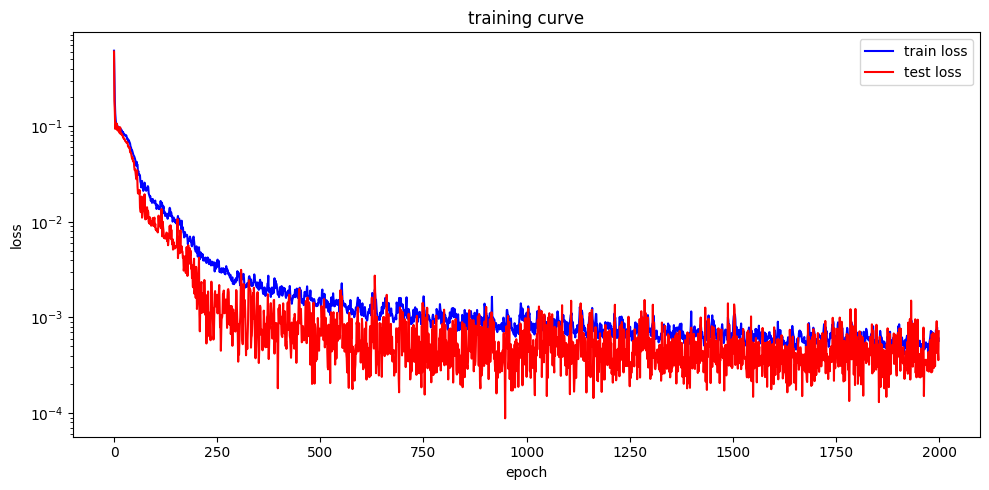

Final train loss: 0.000570
Final test loss: 0.000719


In [7]:
# instantiate model and all that
my_model = SimpleTransformer()
optimizer = optim.Adam(my_model.parameters(), lr=lr)
loss_function = nn.MSELoss()

train_losses = []
test_losses = []

for epoch in range(epochs):
    my_model.train()
    train_loss = 0
    for params, targets in train_loader:
        optimizer.zero_grad()
        outputs = my_model(params)
        loss = loss_function(outputs, targets)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    
    # test
    my_model.eval()
    test_loss = 0
    with torch.no_grad():
        for params, targets in test_loader:
            outputs = my_model(params)
            loss = loss_function(outputs, targets)
            test_loss += loss.item()
    
    train_losses.append(train_loss / len(train_loader))
    test_losses.append(test_loss / len(test_loader))
    
    if epoch % 100 == 0:
        print(f"Epoch {epoch}: Train Loss = {train_losses[-1]:.4f}, Test Loss = {test_losses[-1]:.4f}")

# Plot losses
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(train_losses, label='train loss', c='blue')
ax.plot(test_losses, label='test loss', c='red')
ax.set_xlabel('epoch')
ax.set_ylabel('loss')
ax.set_yscale('log')
ax.set_title('training curve')
ax.legend()
plt.tight_layout()
plt.show()

print(f"Final train loss: {train_losses[-1]:.6f}")
print(f"Final test loss: {test_losses[-1]:.6f}")

### 3. train linear field probes

### the probe will find, approximately, Beta = f = beta_vector * alpha + bias

In [8]:
phi_points = np.linspace(0, 1, phi_steps)
true_beta_values = stats.beta.pdf(phi_points, a_viz, b_viz)

In [9]:
#capture activations and beta values for probes

# 500 random (a,b) pairs to probe.
# probe_params will be smn like [[12,34],[5,6],...]

n_probe_samples = 2500
probe_params = np.random.randint(1, 51, size=(n_probe_samples, 2))

# NEW - this ended up not improving the result...
# probe_params = np.random.uniform(1, 50, size=(n_probe_samples, 2)) 


# 90/10 train/test split for probes
n_train = int(0.9 * n_probe_samples)
probe_train_params = probe_params[:n_train]
probe_test_params = probe_params[n_train:]

all_activations = []
all_Beta_values = []

my_model.eval()
with torch.no_grad():
    for i, (a, b) in enumerate(probe_train_params):  
 
        input_tensor = torch.FloatTensor([[a, b]])
        
        # hook is the cool word for spy in an activation layer. 
        # output[0,0,:] means we take the activations for the first (and only) item in the batch and the first (and only) token in the sequence
        # transformer layers output shape (batch_size, seq_len, feature_dim)
        activations = []
        def hook(module, input, output):
            activations.append(output[0, 0, :].numpy())
        

        #put in hook and also store a handle so we can remove the hook
        handle = my_model.transformer.layers[-1].register_forward_hook(hook)
        # run one of the random 500 (a,b) pairs
        my_model(input_tensor)
        # remember the activation at the end of layer 2
        all_activations.append(activations[0])
        # remove the hook
        handle.remove()
        
        # compute beta values at all phi points for this random (a,b). e.g. Beta(φ; a, b)= 1.4 
        beta_vals = stats.beta.pdf(phi_points, a, b)
        all_Beta_values.append(beta_vals)

all_activations = np.array(all_activations)  # shape: (450, 512)
all_Beta_values = np.array(all_Beta_values)  # Shape: (450, 1000)

below is linear regression: n  
for each .001 step between [0,1], find ideal feature scalar  
f = beta * activations + bias  
probe.coef_ gives the 512 weights  
probe.intercept_ gives the bias term  (altho we don't care about this)  
we just care what dicection probe_coef_ (aka "beta(phi)") is the feature vector  
(the more alpha aligns w/ this, the bigger Beta)  
u can imagine alpha on XY and Beta on Z, then just doing line of best fit.

In [10]:
# training the 1000 linear probes, one for each phi point
feature_vectors = []
feature_biases = []

for i in range(phi_steps):
    
    probe = LinearRegression(fit_intercept=True)
    probe.fit(all_activations, all_Beta_values[:, i]) # 
    
    feature_vectors.append(probe.coef_)
    feature_biases.append(probe.intercept_)


feature_vector_matrix = np.array(feature_vectors)  # Shape: (1000, 512)
feature_biases = np.array(feature_biases)

### 4. pca on the manifold to get top basis vectors

### idea: 
### - take each 512D feature vectors, 
### - shrink em to 30D, 
### - if u take the i-th entry of all 30D vectors, u get the i-th eigenfunction


In [11]:
# alpha_viz for later use
# it's a 512D activation vector for the a,b choice we care to visualize
my_model.eval()
with torch.no_grad():
    input_tensor = torch.FloatTensor([[a_viz, b_viz]])
    activations = []
    def hook(module, input, output):
        activations.append(output[0, 0, :].numpy()) # again, output shape (batch_size, seq_len, feature_dim)
    handle = my_model.transformer.layers[-1].register_forward_hook(hook)
    my_model(input_tensor) #this is what runs the model + hook. hook captures activations
    alpha_viz = activations[0]  # the "alpha(a,b)" NEEDED for PCA section
    handle.remove()

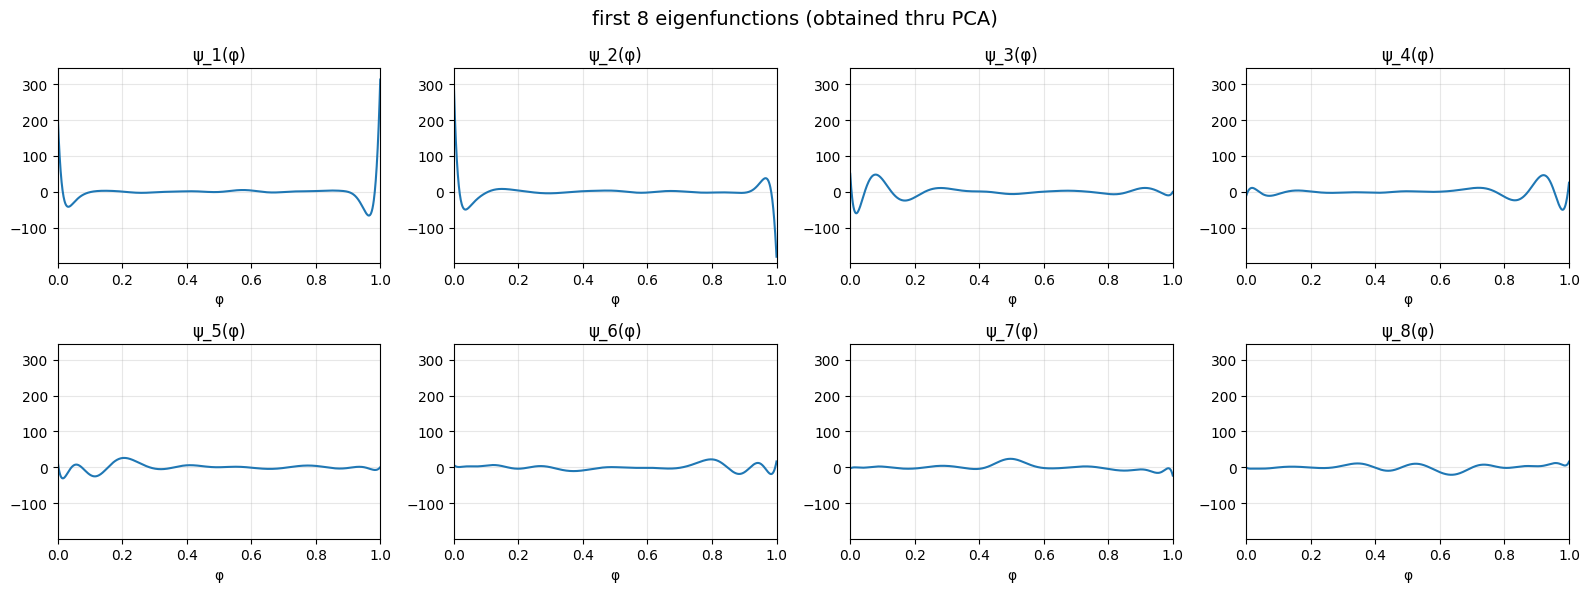

In [12]:
# PCA wants the individual vectors as entries and their 512 dims as subentries
# so feature_vector_matrix is already in the right shape (1000, 512)
#output will be (1000, 30)
# eigenfunction are computed as manifold dot PC_i where PC_i is normalized

pca = PCA(n_components=30)
features_in_PCA_space = pca.fit_transform(feature_vector_matrix)
#now we got 1000 vectors that are 30D. each such vector. 
eigenfunctions = features_in_PCA_space.T 
#this is now 30,1000. each entry is an eigenfunction evaluated at 1000 phi points.


#first 8 eigenfunctions
fig, axes = plt.subplots(2, 4, figsize=(16, 6))

for i, ax in enumerate(axes.flat):
    if i < 8:
        ax.plot(phi_points, eigenfunctions[i,:])
        ax.set_title(f'ψ_{i+1}(φ)', fontsize=12)
        ax.set_xlabel('φ')
        ax.set_xlim(0, 1)
        ax.grid(True, alpha=0.3)
        ax.set_ylim(eigenfunctions[:8, :].min()*1.1, eigenfunctions[:8, :].max()*1.1)

plt.suptitle('first 8 eigenfunctions (obtained thru PCA)', fontsize=14)
plt.tight_layout()
plt.show()

## 5. plot feature fields for differnt # of feature manifold basis vectors 

### idea: 
### f = beta*alpha + bias
### beta = sum c_i PC_i 
### PCA gives u reduced vector 512D->30D.
### (!!!) the c_i's in the 30D vectors describe beta_512 = sum_i c_i PC_i
### in our case we have 1000 such vectors.
### the eigenfunctions matrix has eigenfunctions as entries (1000 phi subentries for each PC)
### thus transpose of eigenfunctions matrix gives the 30D vectors that contain all the c_i's (one 30D vector for each phi)
### so u wanna reconstruct f for each phi as f_phi = (c_i PC_i) @ alpha + bias
# and u wanna see how reconstruction improves the more PC's u account for

In [13]:
# β(φᵢ)_vector = ψ₁(φᵢ)*PC₁_vector + ψ₂(φᵢ)*PC₂_vrctor +...

principal_components = pca.components_  # Shape: (30, 512), normalized
f_functions_dif_amounts_of_eigenfunctions_dict = {}

for k in list(range(1, 31)):
   # (1000, k) @ (k, 512) = (1000, 512)
   # ie, at each phi point, multiply the PCs by the eigenfunctions. then u get a 512D vector at each phi point
    feature_vectors_reconstructed_some_amount_eigenfunctions = eigenfunctions[:k, :].T @ principal_components[:k, :]
    
    # then multiply beta_vector_reconstructed by the activation.
    # NOTE! i shud consider adding in the bias term,.... but first ill focus on getting the shape right...
    f_some_amount_eigenfucntions = feature_vectors_reconstructed_some_amount_eigenfunctions @ alpha_viz + feature_biases
    
    f_functions_dif_amounts_of_eigenfunctions_dict[k] = f_some_amount_eigenfucntions

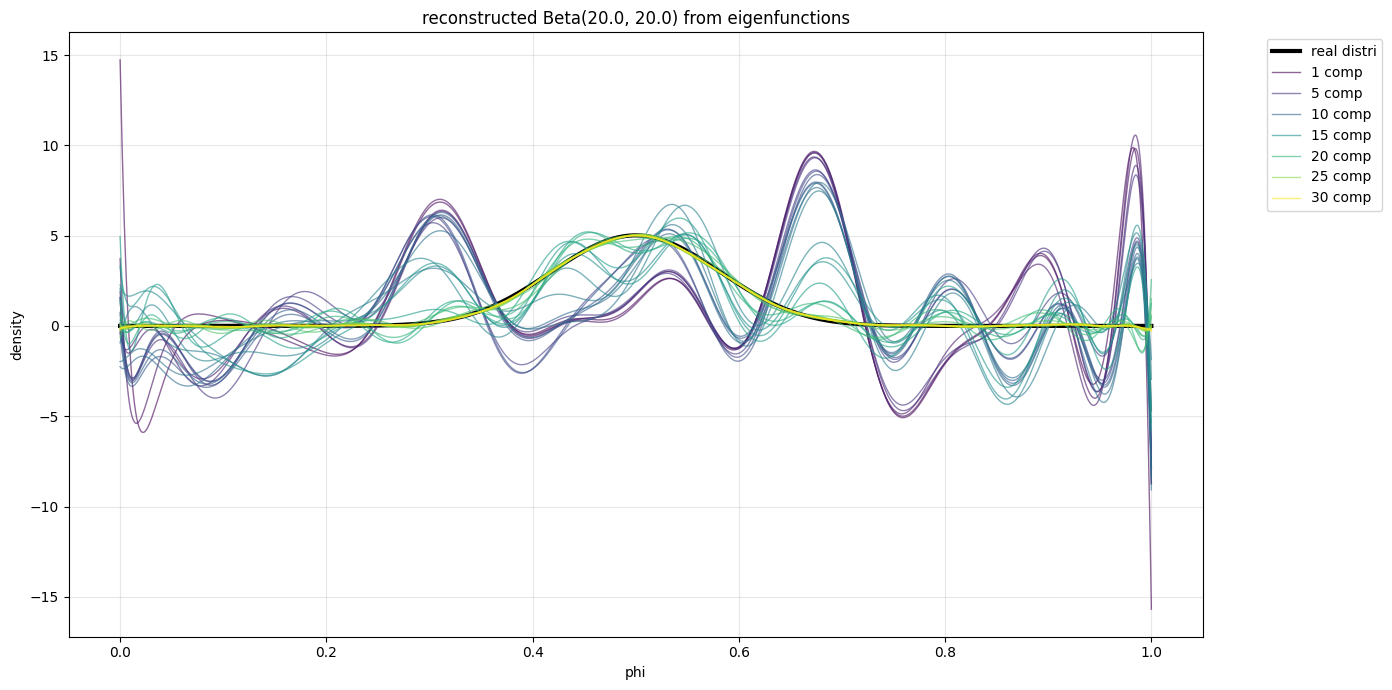

In [14]:
plt.figure(figsize=(14, 7))
colors = plt.cm.viridis(np.linspace(0, 1, len(range(1, 31))))
# true distribution
plt.plot(phi_points, true_beta_values, 'k-', linewidth=3, label='real distri')
#30 reconstructions
for i, k in enumerate(range(1, 31)):
    plt.plot(phi_points, f_functions_dif_amounts_of_eigenfunctions_dict[k], color=colors[i], 
             alpha=0.6, linewidth=1, label=f'{k} comp' if k in [1,5,10,15,20,25,30] else "")

plt.xlabel('phi')
plt.ylabel('density')
plt.title(f'reconstructed Beta({a_viz}, {b_viz}) from eigenfunctions')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Using test sample: (a, b) = (45, 32)


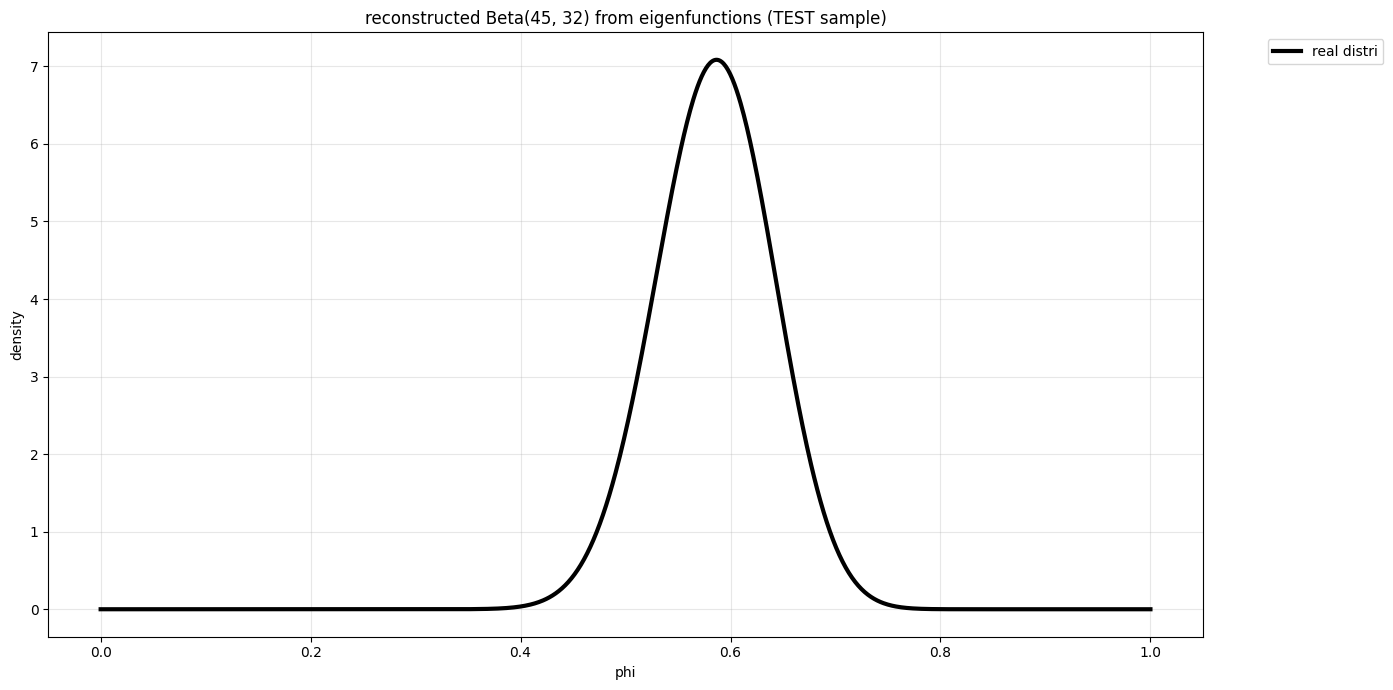

In [15]:
# Pick a random (a,b) from TEST set
#np.random.seed(123)  # for reproducibility, change or remove for different sample
test_idx = np.random.randint(len(test_params))
a_viz, b_viz = test_params[test_idx]
print(f"Using test sample: (a, b) = ({a_viz}, {b_viz})")

# Recompute true beta and activation for this test sample
true_beta_values = stats.beta.pdf(phi_points, a_viz, b_viz)

my_model.eval()
with torch.no_grad():
    input_tensor = torch.FloatTensor([[a_viz, b_viz]])
    activations = []
    def hook(module, input, output):
        activations.append(output[0, 0, :].numpy())
    handle = my_model.transformer.layers[-1].register_forward_hook(hook)
    my_model(input_tensor)
    alpha_viz = activations[0]
    handle.remove()

# Recompute reconstructions with different numbers of eigenfunctions
f_functions_dif_amounts_of_eigenfunctions_dict = {}
#for k in list(range(1, 31)):
  ##  feature_vectors_reconstructed = eigenfunctions[:k, :].T @ principal_components[:k, :]
   # f_some_amount = feature_vectors_reconstructed @ alpha_viz + feature_biases
  #  f_functions_dif_amounts_of_eigenfunctions_dict[k] = f_some_amount

# Plot
plt.figure(figsize=(14, 7))
colors = plt.cm.viridis(np.linspace(0, 1, len(range(1, 31))))
plt.plot(phi_points, true_beta_values, 'k-', linewidth=3, label='real distri')
#for i, k in enumerate(range(25, 31)):
   # plt.plot(phi_points, f_functions_dif_amounts_of_eigenfunctions_dict[k], color=colors[i], 
   #          alpha=0.6, linewidth=1, label=f'{k} comp' if k in [1,5,10,15,20,25,30] else "")
plt.xlabel('phi')
plt.ylabel('density')
plt.title(f'reconstructed Beta({a_viz}, {b_viz}) from eigenfunctions (TEST sample)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Using TEST sample: (a, b) = (34, 31)
Collected activations for 1500 samples

Training probes at each layer...
  input_proj... mean loss = 3.163858
  layer0_norm1... mean loss = 2.523475
  layer0_norm2... mean loss = 0.025918
  layer1_norm1... mean loss = 0.024532
  layer1_norm2... mean loss = 0.008264

Plotting reconstructed Beta distributions...


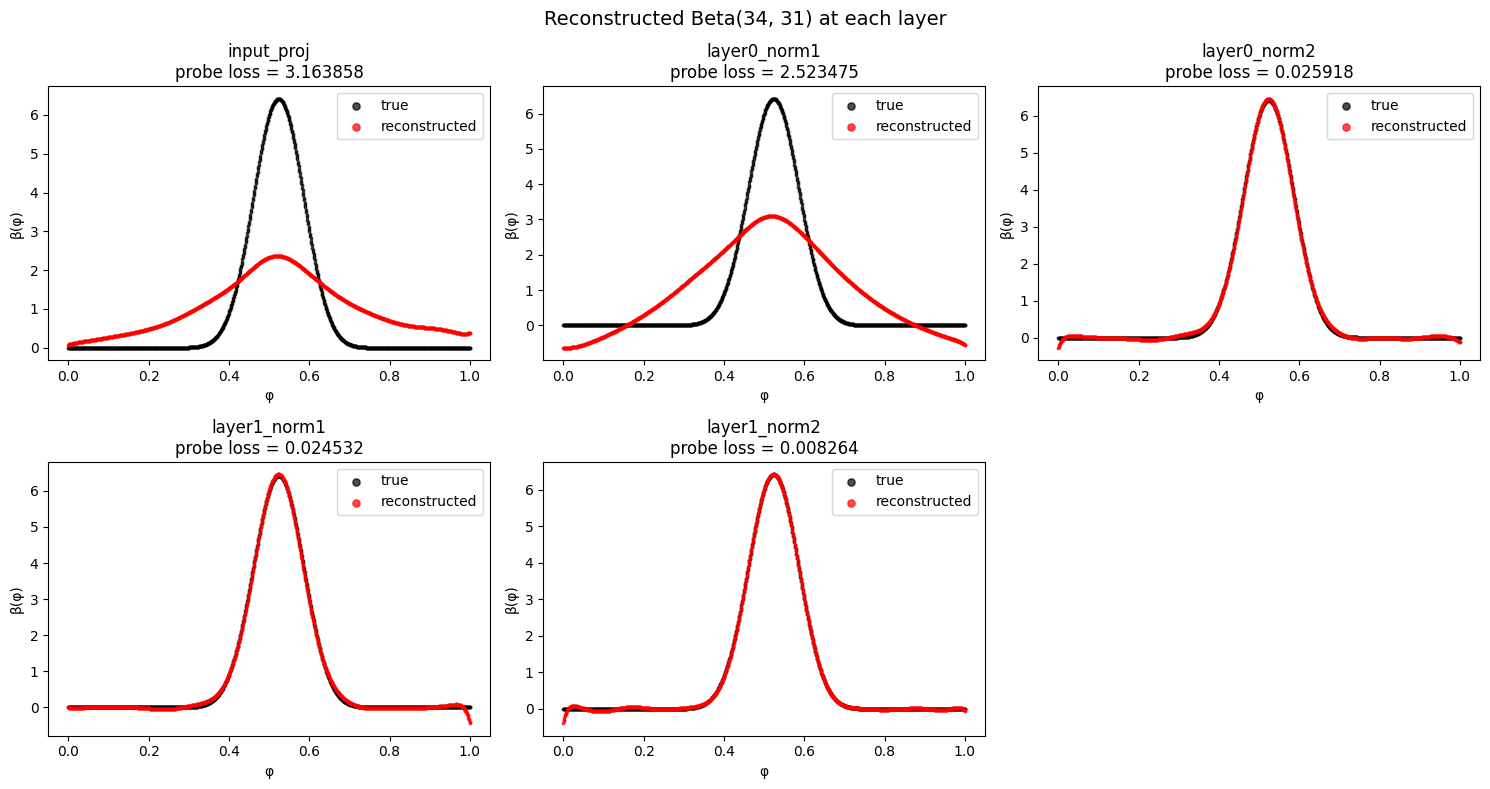

Plotting probe losses by layer...


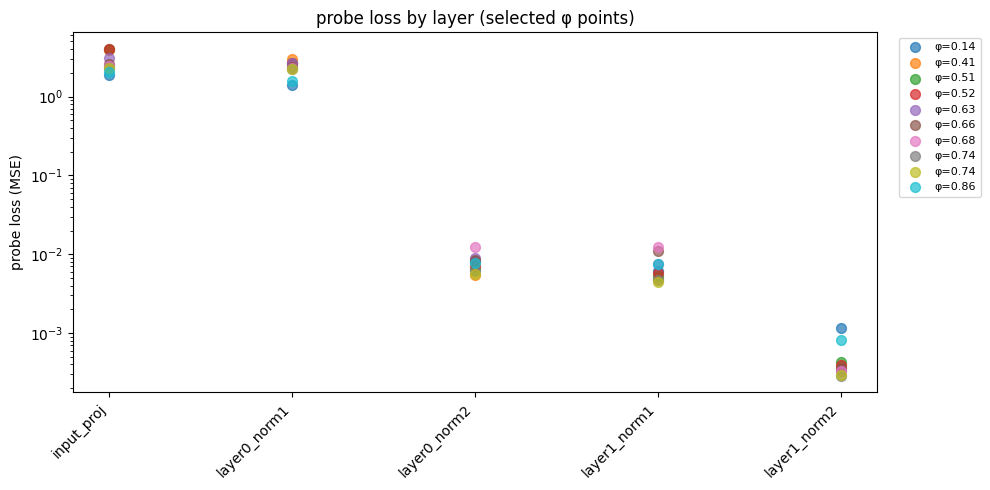

Running causal interventions at each layer...

  Intervention = 10% of β value
    input_proj... corr_single=0.361, corr_integral=0.831
    layer0_norm1... corr_single=-0.243, corr_integral=-0.135
    layer0_norm2... corr_single=0.565, corr_integral=0.552
    layer1_norm1... corr_single=0.105, corr_integral=-0.002
    layer1_norm2... corr_single=0.696, corr_integral=0.565

  Intervention = 20% of β value
    input_proj... corr_single=0.368, corr_integral=0.796
    layer0_norm1... corr_single=-0.217, corr_integral=-0.151
    layer0_norm2... corr_single=0.565, corr_integral=0.551
    layer1_norm1... corr_single=0.105, corr_integral=-0.001
    layer1_norm2... corr_single=0.696, corr_integral=0.565

  Intervention = 50% of β value
    input_proj... corr_single=0.370, corr_integral=0.532
    layer0_norm1... corr_single=-0.108, corr_integral=-0.166
    layer0_norm2... corr_single=0.564, corr_integral=0.551
    layer1_norm1... corr_single=0.103, corr_integral=-0.003
    layer1_norm2... corr_s

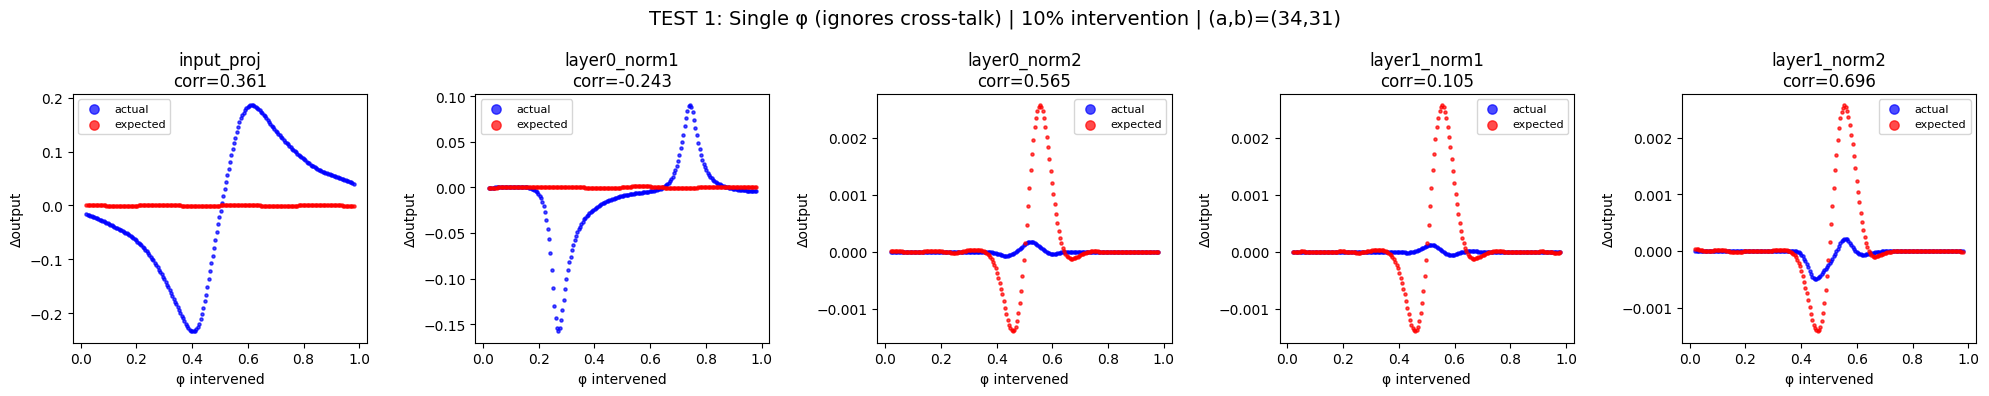

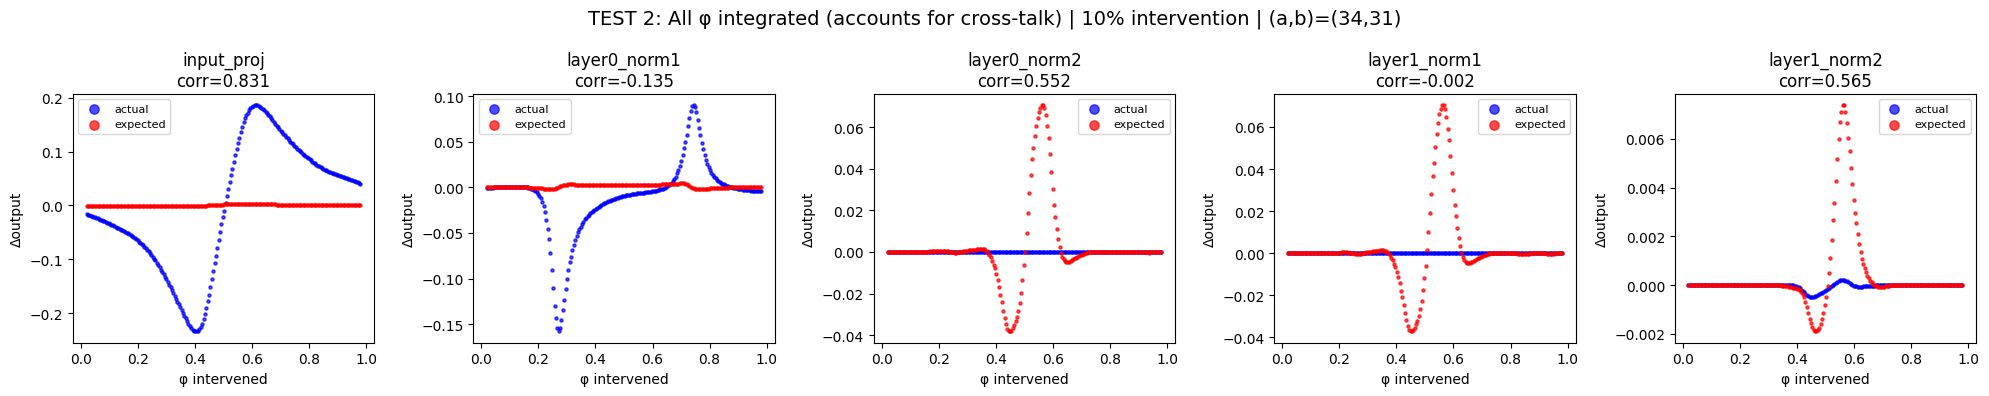

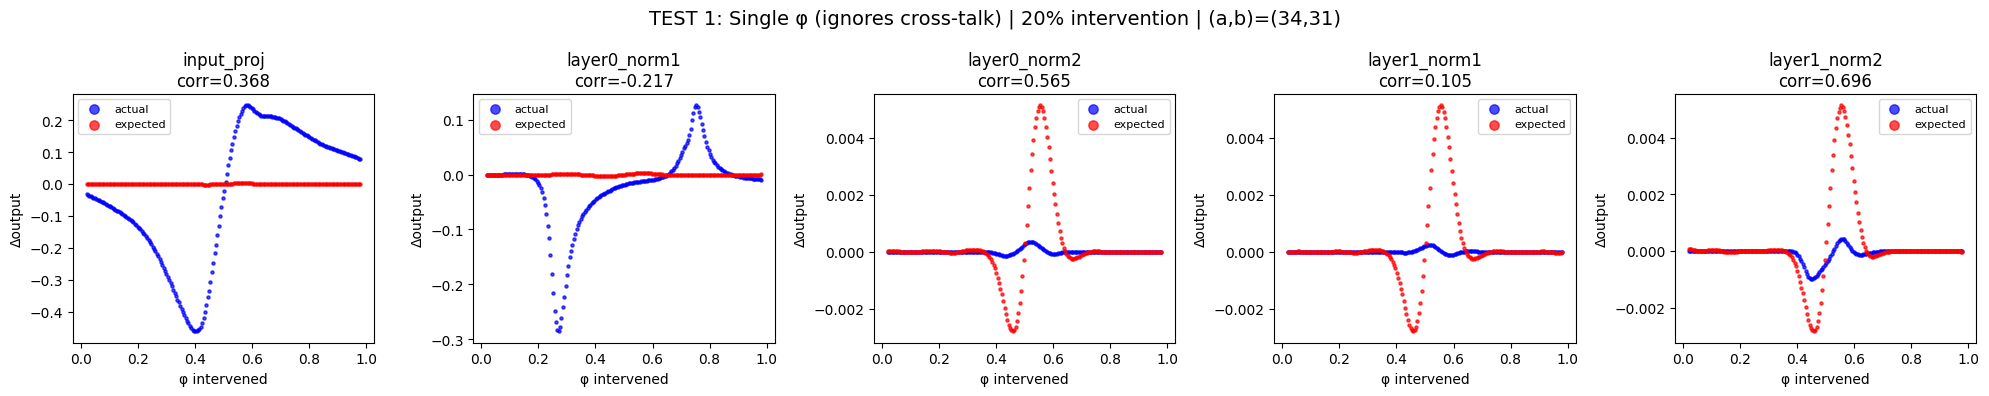

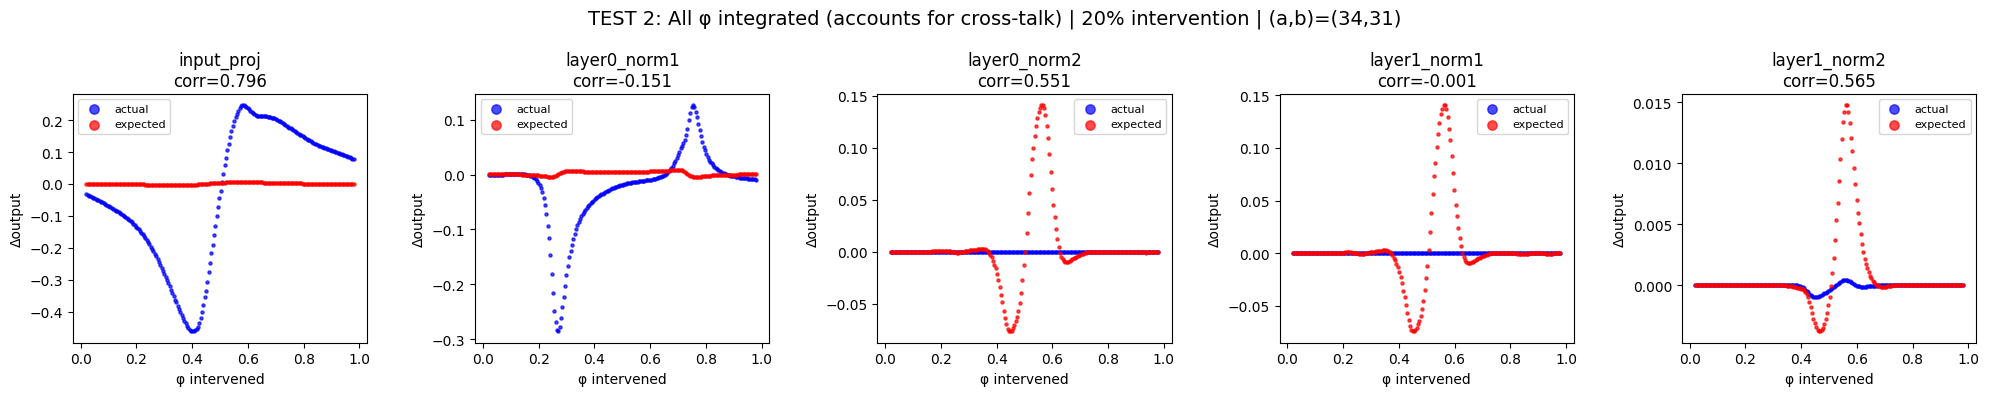

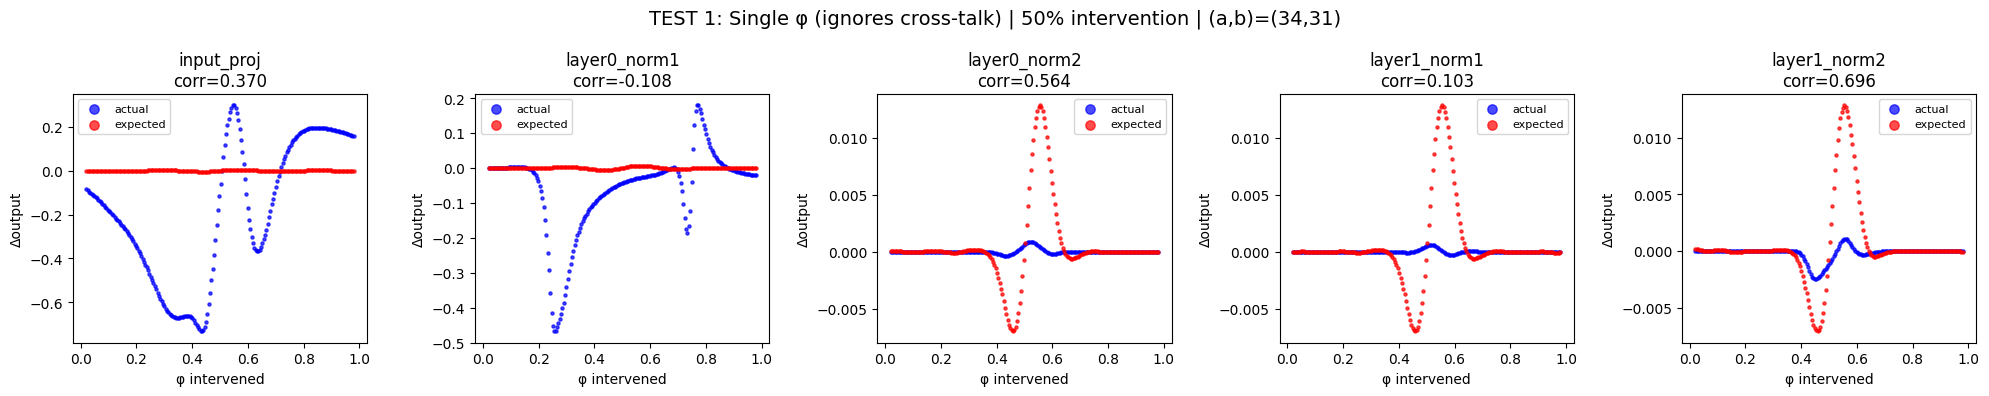

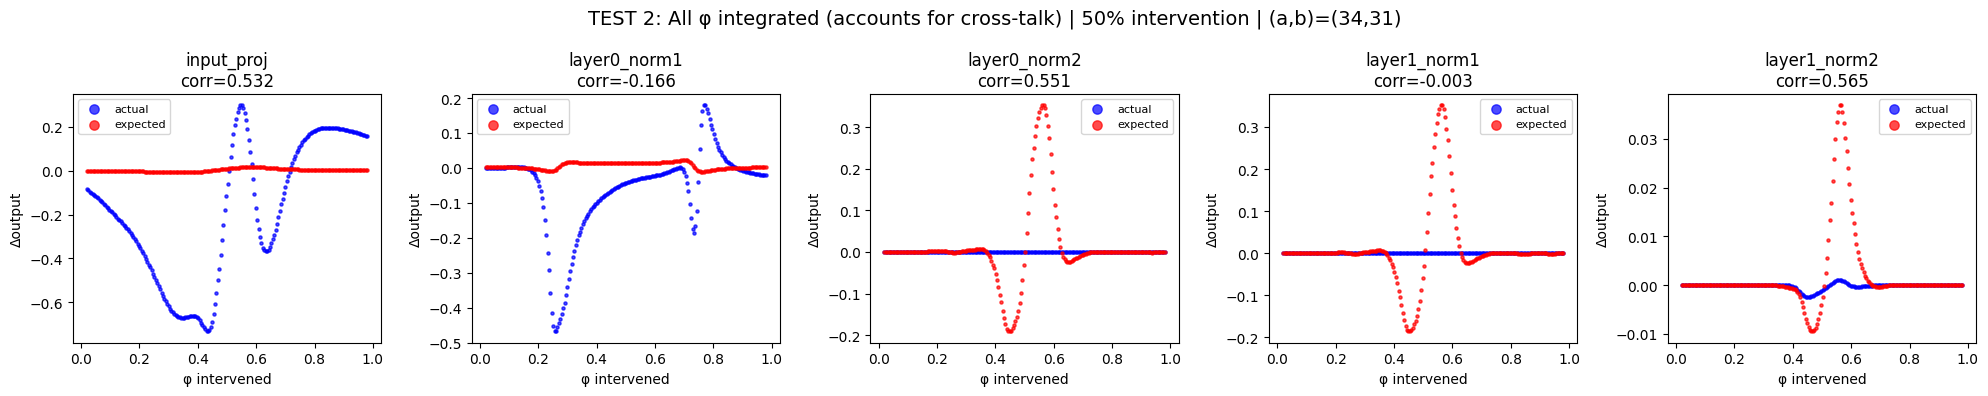

SUMMARY
Sample: (a, b) = (34, 31) from TEST set


Intervention = 10% of β value:
Layer           Probe Loss      Corr (single φ)    Corr (integral)   
------------------------------------------------------------------
input_proj      3.163858        0.361              0.831             
layer0_norm1    2.523475        -0.243             -0.135            
layer0_norm2    0.025918        0.565              0.552             
layer1_norm1    0.024532        0.105              -0.002            
layer1_norm2    0.008264        0.696              0.565             

Intervention = 20% of β value:
Layer           Probe Loss      Corr (single φ)    Corr (integral)   
------------------------------------------------------------------
input_proj      3.163858        0.368              0.796             
layer0_norm1    2.523475        -0.217             -0.151            
layer0_norm2    0.025918        0.565              0.551             
layer1_norm1    0.024532        0.105              -0

In [16]:
# ============================================================
# CONFIG: Choose sample source and random seed
# ============================================================
USE_TEST_SET = True  # True = test set, False = training set
RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)
if USE_TEST_SET:
    sample_idx = np.random.randint(len(test_params))
    a_viz, b_viz = test_params[sample_idx]
    print(f"Using TEST sample: (a, b) = ({a_viz}, {b_viz})")
else:
    sample_idx = np.random.randint(len(train_params))
    a_viz, b_viz = train_params[sample_idx]
    print(f"Using TRAIN sample: (a, b) = ({a_viz}, {b_viz})")

a_test, b_test = a_viz, b_viz

# Intervention percentages to test
INTERVENTION_PERCENTAGES = [10, 20, 50]

# ============================================================
# Hook points
# ============================================================
hook_points = {
    'input_proj': lambda model: model.input_proj,
    'layer0_norm1': lambda model: model.transformer.layers[0].norm1,
    'layer0_norm2': lambda model: model.transformer.layers[0].norm2,
    'layer1_norm1': lambda model: model.transformer.layers[1].norm1,
    'layer1_norm2': lambda model: model.transformer.layers[1].norm2,
}

# ============================================================
# Collect activations at each layer for training probes
# ============================================================
print("Collecting activations at each layer...")
activations_by_layer = {name: [] for name in hook_points}
all_ab_params = []
all_beta_values = []

phi_points = np.linspace(0, 1, phi_steps)

my_model.eval()
with torch.no_grad():
    for a, b in train_params:
        input_tensor = torch.FloatTensor([[a, b]])
        
        for layer_name, get_module in hook_points.items():
            activations = []
            def hook(module, input, output):
                if isinstance(output, tuple):
                    activations.append(output[0][0, 0, :].detach().numpy().copy())
                else:
                    activations.append(output[0, 0, :].detach().numpy().copy())
            
            handle = get_module(my_model).register_forward_hook(hook)
            my_model(input_tensor)
            handle.remove()
            activations_by_layer[layer_name].append(activations[0])
        
        all_ab_params.append((a, b))
        beta_vals = stats.beta.pdf(phi_points, a, b)
        all_beta_values.append(beta_vals)

all_beta_values = np.array(all_beta_values)
for name in activations_by_layer:
    activations_by_layer[name] = np.array(activations_by_layer[name])

print(f"Collected activations for {len(all_ab_params)} samples")
print()

# ============================================================
# Train probes at each layer
# ============================================================
print("Training probes at each layer...")
probes_by_layer = {}
probe_losses_by_layer = {}

for layer_name in hook_points:
    print(f"  {layer_name}...", end=" ")
    
    acts = activations_by_layer[layer_name]
    feature_vectors = []
    feature_biases = []
    losses = []
    
    n_train = int(0.8 * len(acts))
    acts_train, acts_test = acts[:n_train], acts[n_train:]
    beta_train, beta_test = all_beta_values[:n_train], all_beta_values[n_train:]
    
    for i in range(phi_steps):
        probe = LinearRegression(fit_intercept=True)
        probe.fit(acts_train, beta_train[:, i])
        
        feature_vectors.append(probe.coef_)
        feature_biases.append(probe.intercept_)
        
        pred = probe.predict(acts_test)
        mse = np.mean((pred - beta_test[:, i])**2)
        losses.append(mse)
    
    probes_by_layer[layer_name] = {
        'vectors': np.array(feature_vectors),
        'biases': np.array(feature_biases),
        'losses': np.array(losses)
    }
    probe_losses_by_layer[layer_name] = np.mean(losses)
    print(f"mean loss = {np.mean(losses):.6f}")

print()

# ============================================================
# PLOT 1: Reconstructed Beta at each layer
# ============================================================
print("Plotting reconstructed Beta distributions...")

true_beta = stats.beta.pdf(phi_points, a_viz, b_viz)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for idx, layer_name in enumerate(hook_points):
    my_model.eval()
    with torch.no_grad():
        input_tensor = torch.FloatTensor([[a_viz, b_viz]])
        activations = []
        def hook(module, input, output):
            if isinstance(output, tuple):
                activations.append(output[0][0, 0, :].detach().numpy().copy())
            else:
                activations.append(output[0, 0, :].detach().numpy().copy())
        handle = hook_points[layer_name](my_model).register_forward_hook(hook)
        my_model(input_tensor)
        handle.remove()
        h = activations[0]
    
    vectors = probes_by_layer[layer_name]['vectors']
    biases = probes_by_layer[layer_name]['biases']
    reconstructed_beta = h @ vectors.T + biases
    
    ax = axes[idx]
    ax.scatter(phi_points, true_beta, s=3, c='black', alpha=0.7, label='true')
    ax.scatter(phi_points, reconstructed_beta, s=3, c='red', alpha=0.7, label='reconstructed')
    ax.set_xlabel('φ')
    ax.set_ylabel('β(φ)')
    ax.set_title(f'{layer_name}\nprobe loss = {probe_losses_by_layer[layer_name]:.6f}')
    ax.legend(markerscale=3)

if len(hook_points) < 6:
    axes[-1].axis('off')

plt.suptitle(f'Reconstructed Beta({a_viz}, {b_viz}) at each layer', fontsize=14)
plt.tight_layout()
plt.show()

# ============================================================
# PLOT 2: Probe losses by layer (for selected phi points)
# ============================================================
print("Plotting probe losses by layer...")

np.random.seed(42)
phi_viz_indices = np.random.choice(phi_steps, 10, replace=False)
phi_viz_indices = np.sort(phi_viz_indices)

layer_names = list(hook_points.keys())

fig, ax = plt.subplots(figsize=(10, 5))
for phi_idx in phi_viz_indices:
    losses_this_phi = [probes_by_layer[name]['losses'][phi_idx] for name in layer_names]
    ax.scatter(range(len(layer_names)), losses_this_phi, s=50, alpha=0.7, 
               label=f'φ={phi_points[phi_idx]:.2f}')
ax.set_xticks(range(len(layer_names)))
ax.set_xticklabels(layer_names, rotation=45, ha='right')
ax.set_ylabel('probe loss (MSE)')
ax.set_title('probe loss by layer (selected φ points)')
ax.set_yscale('log')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

# ============================================================
# PLOT 3: Causal interventions at each layer
# Loop over intervention percentages
# ============================================================
print("Running causal interventions at each layer...")

phi_test_points = np.linspace(0.02, 0.98, 200)
phi_test_indices = [int(phi * (phi_steps - 1)) for phi in phi_test_points]
delta_phi = phi_test_points[1] - phi_test_points[0]

phi_dense = np.linspace(0, 1, 200)
phi_dense_indices = [int(phi * (phi_steps - 1)) for phi in phi_dense]
cos_dense = np.cos(7 * np.pi * phi_dense)

# Store results for all intervention percentages
all_intervention_results = {}

for pct in INTERVENTION_PERCENTAGES:
    print(f"\n  Intervention = {pct}% of β value")
    all_intervention_results[pct] = {}
    
    for layer_name in hook_points:
        print(f"    {layer_name}...", end=" ")
        
        vectors = probes_by_layer[layer_name]['vectors']
        biases = probes_by_layer[layer_name]['biases']
        
        my_model.eval()
        
        with torch.no_grad():
            input_tensor = torch.FloatTensor([[a_test, b_test]])
            
            baseline_act = []
            def hook(module, input, output):
                if isinstance(output, tuple):
                    baseline_act.append(output[0][0, 0, :].detach().numpy().copy())
                else:
                    baseline_act.append(output[0, 0, :].detach().numpy().copy())
            handle = hook_points[layer_name](my_model).register_forward_hook(hook)
            baseline_output = my_model(input_tensor).item()
            handle.remove()
            h_baseline = baseline_act[0]
        
        actual_deltas = []
        expected_single = []
        expected_integral = []
        
        for phi_idx, phi_val in zip(phi_test_indices, phi_test_points):
            beta_phi = vectors[phi_idx]
            beta_phi_norm = np.linalg.norm(beta_phi)
            beta_phi_normalized = beta_phi / beta_phi_norm
            
            # Current β value at this φ
            beta_current = h_baseline @ beta_phi + biases[phi_idx]
            
            # Intervention strength to get pct% change in β
            # Δβ = beta_current * pct/100
            # Δβ = intervention_strength * ||beta_phi||
            # So: intervention_strength = (beta_current * pct/100) / ||beta_phi||
            target_delta_beta = beta_current * pct / 100
            intervention_strength = target_delta_beta / beta_phi_norm
            
            h_intervened = h_baseline + intervention_strength * beta_phi_normalized
            
            # TEST 1: Δβ at THIS φ only
            beta_intervened_here = h_intervened @ beta_phi + biases[phi_idx]
            delta_beta_here = beta_intervened_here - beta_current
            cos_val = np.cos(7 * np.pi * phi_val)
            expected_single.append(delta_beta_here * cos_val * delta_phi)
            
            # TEST 2: Δβ at ALL φ, then integrate
            delta_beta_all = []
            for phi_idx_dense in phi_dense_indices:
                probe_vec = vectors[phi_idx_dense]
                bias = biases[phi_idx_dense]
                delta = (h_intervened @ probe_vec + bias) - (h_baseline @ probe_vec + bias)
                delta_beta_all.append(delta)
            delta_beta_all = np.array(delta_beta_all)
            expected_integral.append(np.trapezoid(delta_beta_all * cos_dense, phi_dense))
            
            # Actual: intervene and measure
            def make_hook(intervention_vec, strength):
                def hook(module, input, output):
                    if isinstance(output, tuple):
                        new_out = output[0].clone()
                        new_out[0, 0, :] += strength * torch.FloatTensor(intervention_vec)
                        return (new_out,) + output[1:]
                    else:
                        return output + strength * torch.FloatTensor(intervention_vec).unsqueeze(0).unsqueeze(0)
                return hook
            
            with torch.no_grad():
                handle = hook_points[layer_name](my_model).register_forward_hook(
                    make_hook(beta_phi_normalized, intervention_strength)
                )
                actual_output = my_model(input_tensor).item()
                handle.remove()
            
            actual_deltas.append(actual_output - baseline_output)
        
        actual_deltas = np.array(actual_deltas)
        expected_single = np.array(expected_single)
        expected_integral = np.array(expected_integral)
        
        corr_single = np.corrcoef(expected_single, actual_deltas)[0, 1]
        corr_integral = np.corrcoef(expected_integral, actual_deltas)[0, 1]
        
        all_intervention_results[pct][layer_name] = {
            'actual': actual_deltas,
            'expected_single': expected_single,
            'expected_integral': expected_integral,
            'phi': phi_test_points,
            'corr_single': corr_single,
            'corr_integral': corr_integral
        }
        print(f"corr_single={corr_single:.3f}, corr_integral={corr_integral:.3f}")

print()

# Plot for each intervention percentage
for pct in INTERVENTION_PERCENTAGES:
    intervention_results = all_intervention_results[pct]
    
    # TEST 1 (single φ) - bottom row only
    fig, axes = plt.subplots(1, len(hook_points), figsize=(4*len(hook_points), 4))
    
    for idx, layer_name in enumerate(hook_points):
        data = intervention_results[layer_name]
        ax = axes[idx]
        ax.scatter(data['phi'], data['actual'], s=5, c='blue', alpha=0.7, label='actual')
        ax.scatter(data['phi'], data['expected_single'], s=5, c='red', alpha=0.7, label='expected')
        ax.set_xlabel('φ intervened')
        ax.set_ylabel('Δoutput')
        ax.set_title(f'{layer_name}\ncorr={data["corr_single"]:.3f}')
        ax.legend(fontsize=8, markerscale=3)
    
    plt.suptitle(f'TEST 1: Single φ (ignores cross-talk) | {pct}% intervention | (a,b)=({a_test},{b_test})', fontsize=14)
    plt.tight_layout()
    plt.show()
    
    # TEST 2 (all φ integrated) - bottom row only
    fig, axes = plt.subplots(1, len(hook_points), figsize=(4*len(hook_points), 4))
    
    for idx, layer_name in enumerate(hook_points):
        data = intervention_results[layer_name]
        ax = axes[idx]
        ax.scatter(data['phi'], data['actual'], s=5, c='blue', alpha=0.7, label='actual')
        ax.scatter(data['phi'], data['expected_integral'], s=5, c='red', alpha=0.7, label='expected')
        ax.set_xlabel('φ intervened')
        ax.set_ylabel('Δoutput')
        ax.set_title(f'{layer_name}\ncorr={data["corr_integral"]:.3f}')
        ax.legend(fontsize=8, markerscale=3)
    
    plt.suptitle(f'TEST 2: All φ integrated (accounts for cross-talk) | {pct}% intervention | (a,b)=({a_test},{b_test})', fontsize=14)
    plt.tight_layout()
    plt.show()

# Summary table
print("="*90)
print("SUMMARY")
print("="*90)
print(f"Sample: (a, b) = ({a_test}, {b_test}) from {'TEST' if USE_TEST_SET else 'TRAIN'} set")
print()

for pct in INTERVENTION_PERCENTAGES:
    print(f"\nIntervention = {pct}% of β value:")
    print(f"{'Layer':<15} {'Probe Loss':<15} {'Corr (single φ)':<18} {'Corr (integral)':<18}")
    print("-"*66)
    for layer_name in hook_points:
        print(f"{layer_name:<15} {probe_losses_by_layer[layer_name]:<15.6f} "
              f"{all_intervention_results[pct][layer_name]['corr_single']:<18.3f} "
              f"{all_intervention_results[pct][layer_name]['corr_integral']:<18.3f}")

print()
print("="*90)
print("Interpretation:")
print("  - Low probe loss = β(φ) is representable at that layer")
print("  - High corr = expected matches actual → β(φ) is causal")
print("  - Low corr = β(φ) is representable but NOT causal")
print("="*90)

Computing targets for all samples...
Target shapes: (1500, 1000)

Training probes for each target type...
  β(φ)... mean loss = 0.008264
  β(φ)²... mean loss = 16.452211
  sin(β(φ))... mean loss = 0.007163
  √β(φ)... mean loss = 0.000178
  constant=1... mean loss = 0.000000
  Gaussian... mean loss = 0.001276
  φ²... mean loss = 0.000000
  φ³... mean loss = 0.000000

VERIFYING TRAIN/TEST SPLIT
Train params: 1500 samples
Test params: 1000 samples
Overlap: 0 samples
✓ No overlap — train/test split is clean

Plotting reconstructions...
✓ Confirmed: test sample (47, 42) is NOT in training set

  Plotting TRAIN sample: (a,b) = (6, 35)


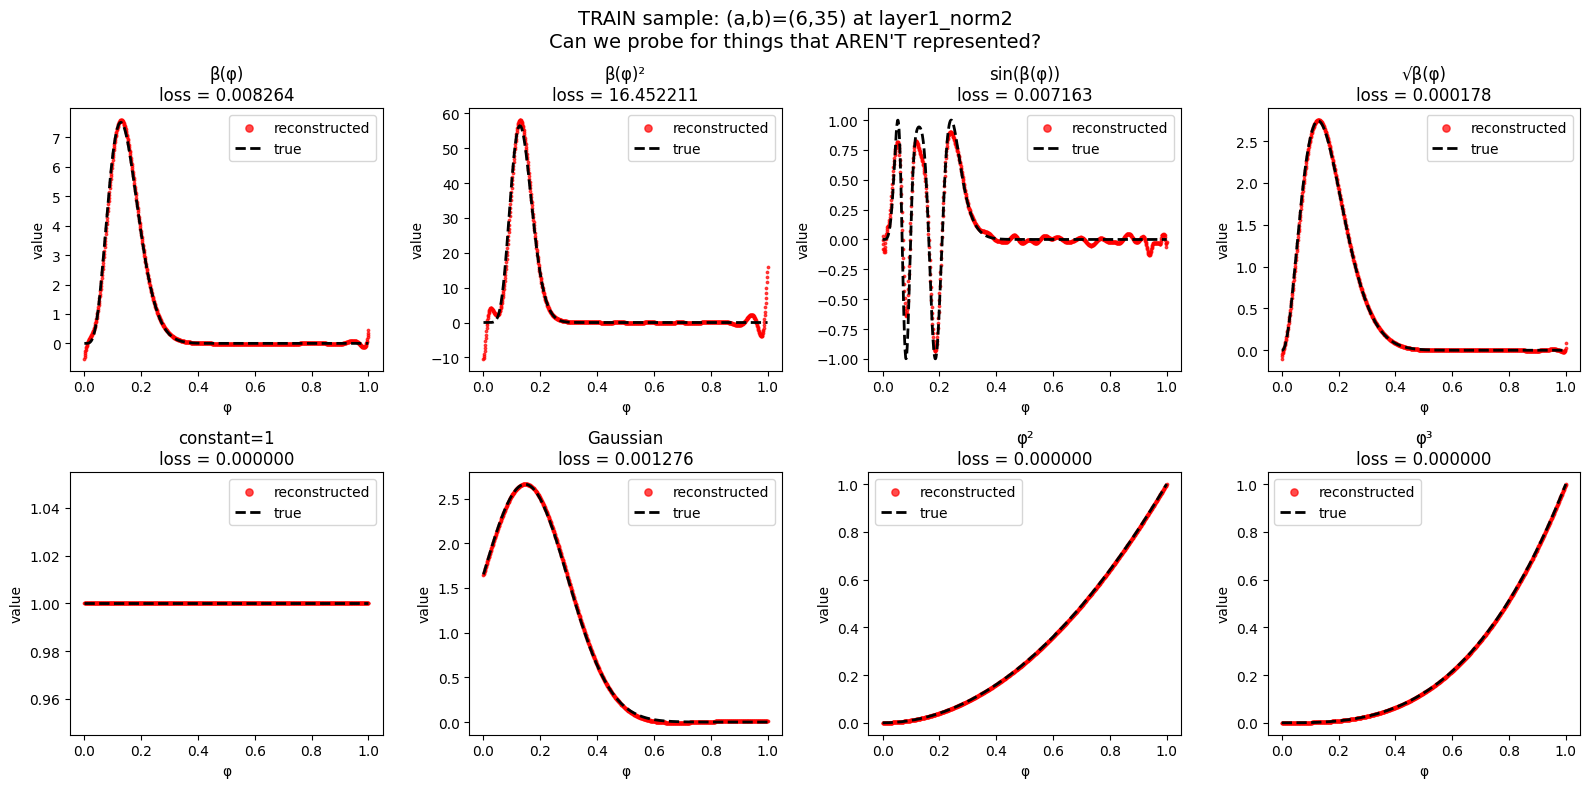

  Plotting TEST sample: (a,b) = (47, 42)


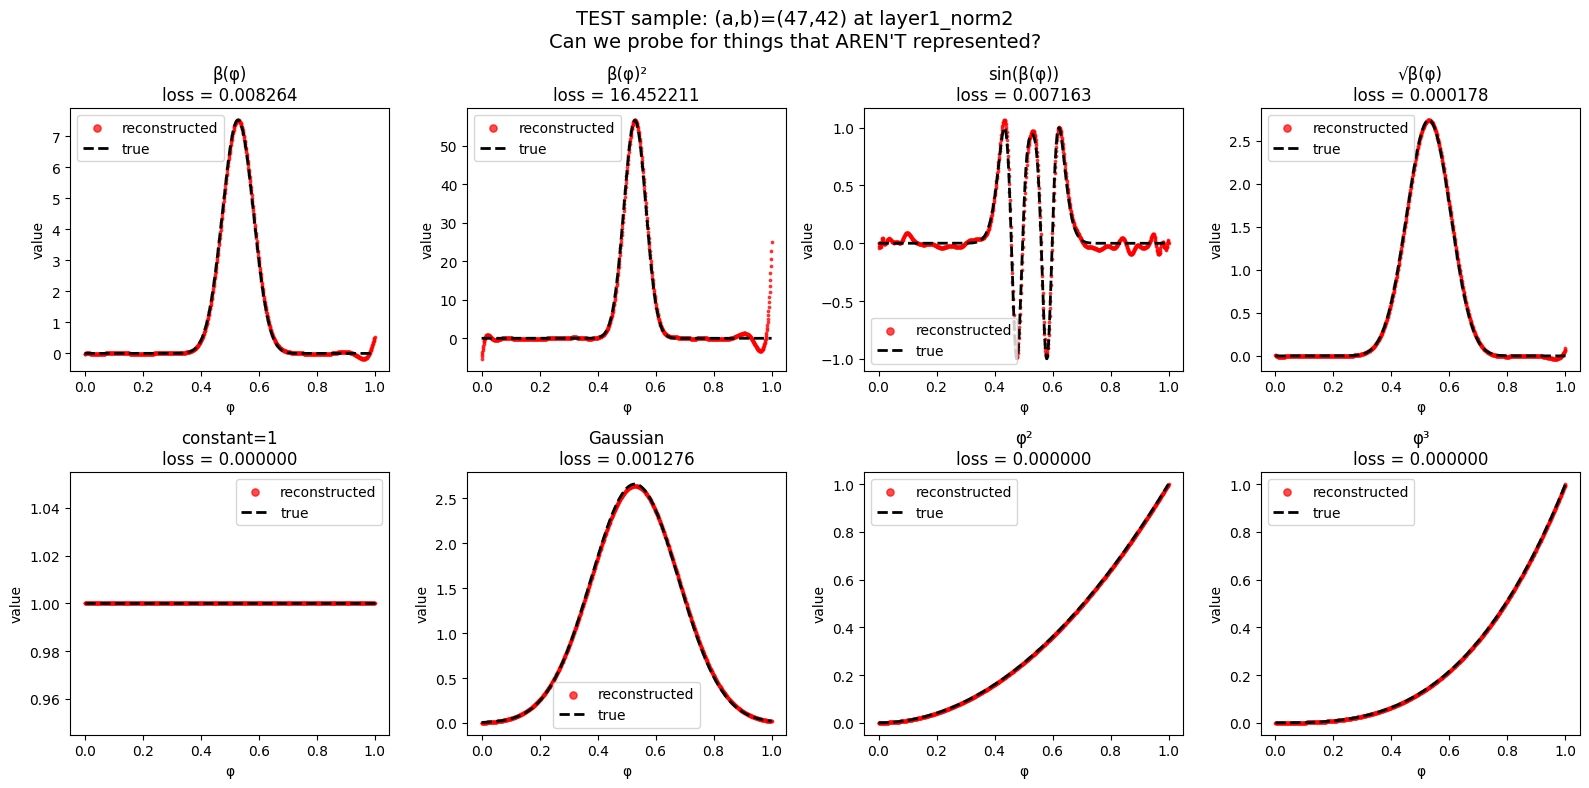

SUMMARY: Representability of various targets
Target               Mean Probe Loss
-----------------------------------
β(φ)                 0.008264       
β(φ)²                16.452211      
sin(β(φ))            0.007163       
√β(φ)                0.000178       
constant=1           0.000000       
Gaussian             0.001276       
φ²                   0.000000       
φ³                   0.000000       

Key insight:
  If non-represented targets (like β², sin(β), √β, Gaussian, φ², φ³)
  have LOW probe loss, it shows that 'representable' ≠ 'represented'.
  Linear probes can find things that the model doesn't actually compute.


In [17]:
# ============================================================
# REPRESENTABILITY TEST: Can we probe for things that AREN'T represented?
# ============================================================

# Use layer1_norm2 (where β(φ) probes worked best)
layer_name = 'layer1_norm2'
acts = activations_by_layer[layer_name]

n_train = int(0.8 * len(acts))
acts_train, acts_test = acts[:n_train], acts[n_train:]

# Define all target functions
def compute_targets(a, b, phi_points):
    """Compute various target distributions for given (a,b)"""
    targets = {}
    
    # 1. True β(φ) — baseline
    beta_vals = stats.beta.pdf(phi_points, a, b)
    targets['β(φ)'] = beta_vals
    
    # 2. β(φ)² — squared
    targets['β(φ)²'] = beta_vals ** 2
    
    # 3. sin(β(φ)) — nonlinear transform
    targets['sin(β(φ))'] = np.sin(beta_vals)
    
    # 4. √β(φ) — square root
    targets['√β(φ)'] = np.sqrt(beta_vals)
    
    # 5. Constant = 1
    targets['constant=1'] = np.ones_like(phi_points)
    
    # 6. Gaussian centered at a/(a+b)
    mu = a / (a + b)
    sigma = 0.15
    targets['Gaussian'] = stats.norm.pdf(phi_points, mu, sigma)
    
    # 7. φ² — just the domain squared
    targets['φ²'] = phi_points ** 2
    
    # 8. φ³ — domain cubed
    targets['φ³'] = phi_points ** 3
    
    return targets

# Compute targets for all training samples
print("Computing targets for all samples...")
all_targets = {name: [] for name in compute_targets(1, 1, phi_points).keys()}

for a, b in all_ab_params:
    targets = compute_targets(a, b, phi_points)
    for name, vals in targets.items():
        all_targets[name].append(vals)

for name in all_targets:
    all_targets[name] = np.array(all_targets[name])

print(f"Target shapes: {all_targets['β(φ)'].shape}")
print()

# Train probes for each target type
print("Training probes for each target type...")
probes_by_target = {}
losses_by_target = {}

for target_name in all_targets:
    print(f"  {target_name}...", end=" ")
    
    target_train = all_targets[target_name][:n_train]
    target_test = all_targets[target_name][n_train:]
    
    feature_vectors = []
    feature_biases = []
    losses = []
    
    for i in range(phi_steps):
        probe = LinearRegression(fit_intercept=True)
        probe.fit(acts_train, target_train[:, i])
        
        feature_vectors.append(probe.coef_)
        feature_biases.append(probe.intercept_)
        
        pred = probe.predict(acts_test)
        mse = np.mean((pred - target_test[:, i])**2)
        losses.append(mse)
    
    probes_by_target[target_name] = {
        'vectors': np.array(feature_vectors),
        'biases': np.array(feature_biases),
        'losses': np.array(losses)
    }
    losses_by_target[target_name] = np.mean(losses)
    print(f"mean loss = {np.mean(losses):.6f}")

print()

# ============================================================
# VERIFY TRAIN/TEST SPLIT
# ============================================================
print("="*70)
print("VERIFYING TRAIN/TEST SPLIT")
print("="*70)

train_set = set(tuple(p) for p in train_params)
test_set = set(tuple(p) for p in test_params)
overlap = train_set & test_set

print(f"Train params: {len(train_params)} samples")
print(f"Test params: {len(test_params)} samples")
print(f"Overlap: {len(overlap)} samples")

if len(overlap) == 0:
    print("✓ No overlap — train/test split is clean")
else:
    print("✗ WARNING: Overlap detected!")
    
print("="*70)
print()

# ============================================================
# PLOT: Reconstructed vs True for each target
# Separate figures for TRAIN and TEST samples
# ============================================================
print("Plotting reconstructions...")

# Pick random samples from train and test
np.random.seed(123)
train_sample_idx = np.random.randint(len(train_params))
a_train, b_train = train_params[train_sample_idx]

test_sample_idx = np.random.randint(len(test_params))
a_test_sample, b_test_sample = test_params[test_sample_idx]

# Double-check test sample is not in train
assert tuple([a_test_sample, b_test_sample]) not in train_set, "Test sample found in train set!"
print(f"✓ Confirmed: test sample ({a_test_sample}, {b_test_sample}) is NOT in training set")
print()

samples = [
    ('TRAIN', a_train, b_train),
    ('TEST', a_test_sample, b_test_sample)
]

for sample_type, a_sample, b_sample in samples:
    print(f"  Plotting {sample_type} sample: (a,b) = ({a_sample}, {b_sample})")
    
    # Get activation for this sample
    my_model.eval()
    with torch.no_grad():
        input_tensor = torch.FloatTensor([[a_sample, b_sample]])
        activations = []
        def hook(module, input, output):
            if isinstance(output, tuple):
                activations.append(output[0][0, 0, :].detach().numpy().copy())
            else:
                activations.append(output[0, 0, :].detach().numpy().copy())
        handle = hook_points[layer_name](my_model).register_forward_hook(hook)
        my_model(input_tensor)
        handle.remove()
        h = activations[0]
    
    # Compute true targets for this sample
    true_targets = compute_targets(a_sample, b_sample, phi_points)
    
    # Plot
    n_targets = len(all_targets)
    n_cols = 4
    n_rows = int(np.ceil(n_targets / n_cols))
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 4*n_rows))
    axes = axes.flatten()
    
    for idx, target_name in enumerate(all_targets.keys()):
        ax = axes[idx]
        
        # True target
        true_vals = true_targets[target_name]
        
        # Reconstructed
        vectors = probes_by_target[target_name]['vectors']
        biases = probes_by_target[target_name]['biases']
        reconstructed = h @ vectors.T + biases
        
        # Plot reconstructed as scatter, true as dashed line on top
        ax.scatter(phi_points, reconstructed, s=3, c='red', alpha=0.7, label='reconstructed')
        ax.plot(phi_points, true_vals, 'k--', linewidth=2, label='true')
        ax.set_xlabel('φ')
        ax.set_ylabel('value')
        ax.set_title(f'{target_name}\nloss = {losses_by_target[target_name]:.6f}')
        ax.legend(markerscale=3)
    
    # Hide extra subplots
    for idx in range(n_targets, len(axes)):
        axes[idx].axis('off')
    
    plt.suptitle(f'{sample_type} sample: (a,b)=({a_sample},{b_sample}) at {layer_name}\n'
                 f'Can we probe for things that AREN\'T represented?', fontsize=14)
    plt.tight_layout()
    plt.show()

# ============================================================
# Summary
# ============================================================
print("="*70)
print("SUMMARY: Representability of various targets")
print("="*70)
print(f"{'Target':<20} {'Mean Probe Loss':<15}")
print("-"*35)
for name in all_targets.keys():
    print(f"{name:<20} {losses_by_target[name]:<15.6f}")
print("="*70)
print()
print("Key insight:")
print("  If non-represented targets (like β², sin(β), √β, Gaussian, φ², φ³)")
print("  have LOW probe loss, it shows that 'representable' ≠ 'represented'.")
print("  Linear probes can find things that the model doesn't actually compute.")
print("="*70)

Computing targets for all samples...
Target shapes: (1500, 1000)

Training probes for each target type...
  β(φ)... mean loss = 0.008264
  β(φ)²... mean loss = 16.452211
  √β(φ)... mean loss = 0.000178
  exp(β(φ)/10)... mean loss = 0.024158
  log(β(φ)+1)... mean loss = 0.000120
  tanh(β(φ))... mean loss = 0.000167
  β(φ)³... mean loss = 29778.272020
  sin(β(φ))... mean loss = 0.007163
  sin(3β(φ))... mean loss = 0.096921
  sin(10β(φ))... mean loss = 0.189494
  cos(5β(φ))... mean loss = 0.156068
  (β(φ) - mean)²... mean loss = 15.129509
  (β(φ) - 1)²... mean loss = 15.159369
  (β(φ) - 2)²... mean loss = 13.932629
  β(φ)·sin(5πφ)... mean loss = 0.000857
  β(φ)·cos(7πφ)... mean loss = 0.007105
  Gaussian(mode)... mean loss = 0.002947
  Gaussian(0.3)... mean loss = 0.000000
  Gaussian(0.7)... mean loss = 0.000000
  Bimodal... mean loss = 0.000000
  sin(a·b/100)... mean loss = 0.229886
  sin(a)·cos(b)... mean loss = 0.284358

SUMMARY: Monotonic vs Non-Monotonic Transforms

MONOTONIC TRANSFO

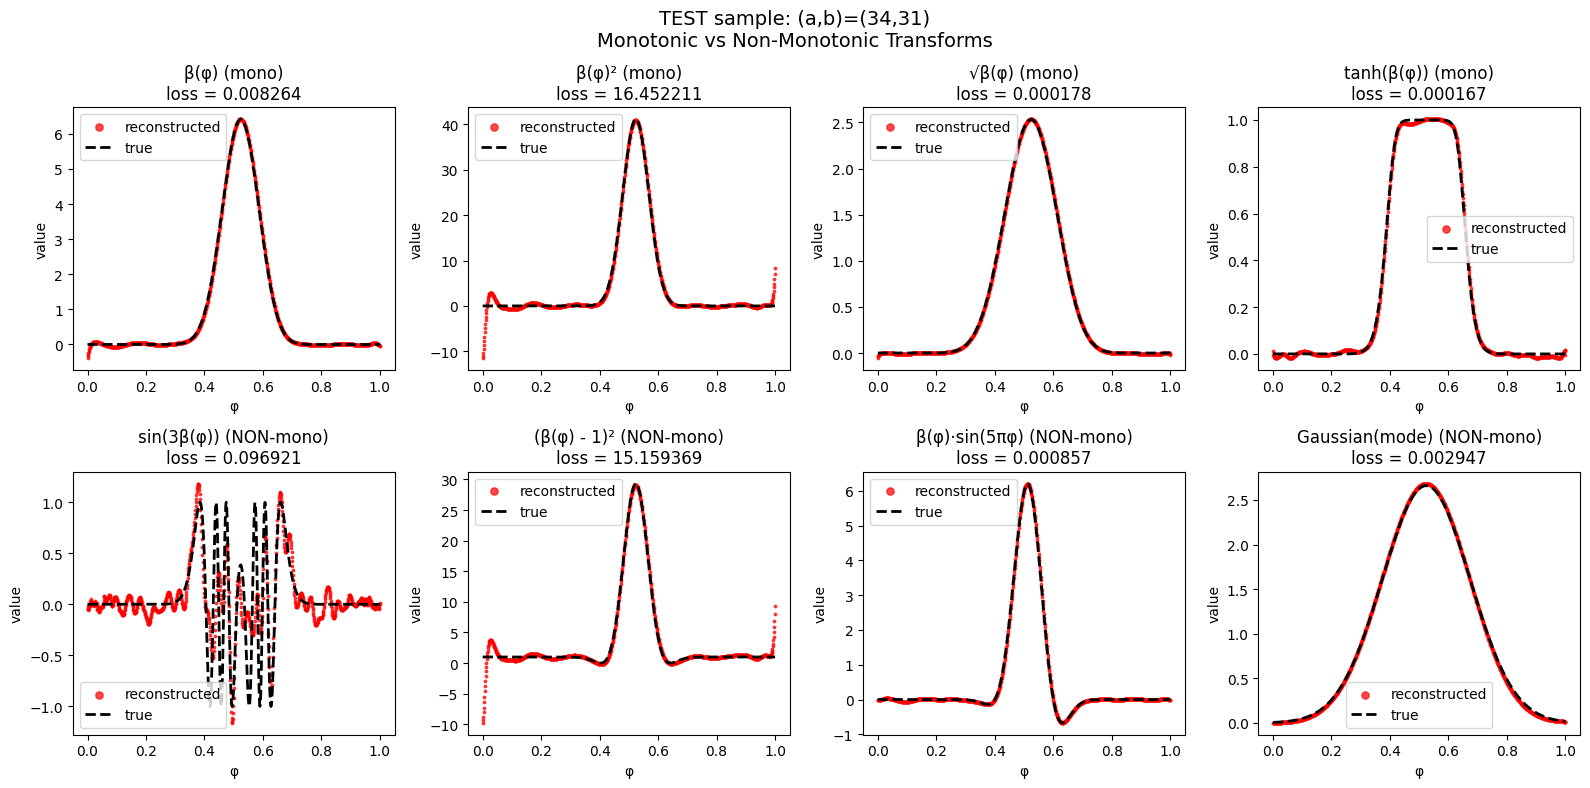

In [18]:
# ============================================================
# REPRESENTABILITY TEST: Monotonic vs Non-Monotonic Transforms
# ============================================================

layer_name = 'layer1_norm2'
acts = activations_by_layer[layer_name]

n_train = int(0.8 * len(acts))
acts_train, acts_test = acts[:n_train], acts[n_train:]

def compute_targets(a, b, phi_points):
    """Compute various target distributions for given (a,b)"""
    targets = {}
    
    # True β(φ) — baseline
    beta_vals = stats.beta.pdf(phi_points, a, b)
    targets['β(φ)'] = beta_vals
    
    # ============================================================
    # MONOTONIC TRANSFORMS (should all work equally well)
    # ============================================================
    targets['β(φ)²'] = beta_vals ** 2
    targets['√β(φ)'] = np.sqrt(beta_vals + 1e-10)
    targets['exp(β(φ)/10)'] = np.exp(beta_vals / 10)  # scaled to avoid overflow
    targets['log(β(φ)+1)'] = np.log(beta_vals + 1)
    targets['tanh(β(φ))'] = np.tanh(beta_vals)
    targets['β(φ)³'] = beta_vals ** 3
    
    # ============================================================
    # NON-MONOTONIC TRANSFORMS (should fail if model only encodes β)
    # ============================================================
    
    # Oscillating transforms of β
    targets['sin(β(φ))'] = np.sin(beta_vals)
    targets['sin(3β(φ))'] = np.sin(3 * beta_vals)
    targets['sin(10β(φ))'] = np.sin(10 * beta_vals)
    targets['cos(5β(φ))'] = np.cos(5 * beta_vals)
    
    # Squared deviations (parabolic = non-monotonic)
    beta_mean = np.mean(beta_vals)
    targets['(β(φ) - mean)²'] = (beta_vals - beta_mean) ** 2
    targets['(β(φ) - 1)²'] = (beta_vals - 1.0) ** 2
    targets['(β(φ) - 2)²'] = (beta_vals - 2.0) ** 2
    
    # Modulated by oscillation in φ
    targets['β(φ)·sin(5πφ)'] = beta_vals * np.sin(5 * np.pi * phi_points)
    targets['β(φ)·cos(7πφ)'] = beta_vals * np.cos(7 * np.pi * phi_points)
    
    # Gaussian centered at mode of beta distribution
    mode = (a - 1) / (a + b - 2) if (a > 1 and b > 1) else 0.5
    targets['Gaussian(mode)'] = stats.norm.pdf(phi_points, mode, 0.15)
    
    # Gaussian NOT centered at mode (arbitrary center)
    targets['Gaussian(0.3)'] = stats.norm.pdf(phi_points, 0.3, 0.15)
    targets['Gaussian(0.7)'] = stats.norm.pdf(phi_points, 0.7, 0.15)
    
    # Completely different distribution shape
    targets['Bimodal'] = stats.norm.pdf(phi_points, 0.3, 0.1) + stats.norm.pdf(phi_points, 0.7, 0.1)
    
    # Random-ish but deterministic function of (a,b)
    targets['sin(a·b/100)'] = np.sin(a * b / 100) * np.ones_like(phi_points) + beta_vals * 0  # constant per (a,b)
    targets['sin(a)·cos(b)'] = np.sin(a) * np.cos(b) * np.ones_like(phi_points) + beta_vals * 0
    
    return targets

# Compute targets for all training samples
print("Computing targets for all samples...")
all_targets = {name: [] for name in compute_targets(10, 10, phi_points).keys()}

for a, b in all_ab_params:
    targets = compute_targets(a, b, phi_points)
    for name, vals in targets.items():
        all_targets[name].append(vals)

for name in all_targets:
    all_targets[name] = np.array(all_targets[name])

print(f"Target shapes: {all_targets['β(φ)'].shape}")
print()

# Train probes for each target type
print("Training probes for each target type...")
probes_by_target = {}
losses_by_target = {}

for target_name in all_targets:
    print(f"  {target_name}...", end=" ")
    
    target_train = all_targets[target_name][:n_train]
    target_test = all_targets[target_name][n_train:]
    
    feature_vectors = []
    feature_biases = []
    losses = []
    
    for i in range(phi_steps):
        probe = LinearRegression(fit_intercept=True)
        probe.fit(acts_train, target_train[:, i])
        
        feature_vectors.append(probe.coef_)
        feature_biases.append(probe.intercept_)
        
        pred = probe.predict(acts_test)
        mse = np.mean((pred - target_test[:, i])**2)
        losses.append(mse)
    
    probes_by_target[target_name] = {
        'vectors': np.array(feature_vectors),
        'biases': np.array(feature_biases),
        'losses': np.array(losses)
    }
    losses_by_target[target_name] = np.mean(losses)
    print(f"mean loss = {np.mean(losses):.6f}")

print()

# ============================================================
# SUMMARY TABLE: Monotonic vs Non-Monotonic
# ============================================================
print("="*70)
print("SUMMARY: Monotonic vs Non-Monotonic Transforms")
print("="*70)

monotonic = ['β(φ)', 'β(φ)²', '√β(φ)', 'exp(β(φ)/10)', 'log(β(φ)+1)', 'tanh(β(φ))', 'β(φ)³']
non_monotonic = [k for k in all_targets.keys() if k not in monotonic]

print("\nMONOTONIC TRANSFORMS (expect similar, low loss):")
print(f"{'Target':<20} {'Mean Probe Loss':<15}")
print("-"*35)
for name in monotonic:
    if name in losses_by_target:
        print(f"{name:<20} {losses_by_target[name]:<15.6f}")

print("\nNON-MONOTONIC TRANSFORMS (expect higher loss if β is truly represented):")
print(f"{'Target':<20} {'Mean Probe Loss':<15}")
print("-"*35)
for name in non_monotonic:
    print(f"{name:<20} {losses_by_target[name]:<15.6f}")

print("="*70)
print()
print("KEY PREDICTION:")
print("  If model specifically represents β(φ):")
print("    → Monotonic transforms: LOW loss (all similar)")
print("    → Non-monotonic transforms: HIGH loss")
print()
print("  If model just encodes 'something correlated with β':")
print("    → ALL transforms may have similar loss")
print("    → This would show Representable ≠ Represented")
print("="*70)

# ============================================================
# PLOT: Reconstructed vs True (subset of interesting ones)
# ============================================================
print("Plotting reconstructions for test sample...")

np.random.seed(42)
test_sample_idx = np.random.randint(len(test_params))
a_test_sample, b_test_sample = test_params[test_sample_idx]
print(f"Test sample: (a, b) = ({a_test_sample}, {b_test_sample})")

# Get activation for this sample
my_model.eval()
with torch.no_grad():
    input_tensor = torch.FloatTensor([[a_test_sample, b_test_sample]])
    activations = []
    def hook(module, input, output):
        if isinstance(output, tuple):
            activations.append(output[0][0, 0, :].detach().numpy().copy())
        else:
            activations.append(output[0, 0, :].detach().numpy().copy())
    handle = hook_points[layer_name](my_model).register_forward_hook(hook)
    my_model(input_tensor)
    handle.remove()
    h = activations[0]

# Compute true targets for this sample
true_targets = compute_targets(a_test_sample, b_test_sample, phi_points)

# Plot selection: baseline + some monotonic + some non-monotonic
plot_targets = ['β(φ)', 'β(φ)²', '√β(φ)', 'tanh(β(φ))',  # monotonic
                'sin(3β(φ))', '(β(φ) - 1)²', 'β(φ)·sin(5πφ)', 'Gaussian(mode)']  # non-monotonic

n_cols = 4
n_rows = 2

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 4*n_rows))
axes = axes.flatten()

for idx, target_name in enumerate(plot_targets):
    ax = axes[idx]
    
    true_vals = true_targets[target_name]
    
    vectors = probes_by_target[target_name]['vectors']
    biases = probes_by_target[target_name]['biases']
    reconstructed = h @ vectors.T + biases
    
    ax.scatter(phi_points, reconstructed, s=3, c='red', alpha=0.7, label='reconstructed')
    ax.plot(phi_points, true_vals, 'k--', linewidth=2, label='true')
    ax.set_xlabel('φ')
    ax.set_ylabel('value')
    
    is_monotonic = target_name in monotonic
    ax.set_title(f'{target_name} ({"mono" if is_monotonic else "NON-mono"})\nloss = {losses_by_target[target_name]:.6f}')
    ax.legend(markerscale=3)

plt.suptitle(f'TEST sample: (a,b)=({a_test_sample},{b_test_sample})\nMonotonic vs Non-Monotonic Transforms', fontsize=14)
plt.tight_layout()
plt.show()


Constrained Belief Updates Explain Geometric Structures in
Transformer Representations